# Task 6 Commercial Replacement Verification: Person & Vehicle Re-ID

**Repo:** `f:\IRIS\surveillance-new`  
**Task 6A (Barber Person Re-ID Replacement):** `occurra/person_reid_siglip2_naflex_512d` (**Apache-2.0**, `512-d` ONNX opset 17, natural aspect-ratio NaFlex) replacing `tao_swin_t` / `tao_resnet50` (`Market-1501` dataset clearance pending) in `perception/modules/appearance/worker.py`.  
*(Note on `OpenVINO person-reidentification-retail-0277`, `Apache-2.0`, `256-d`: Intel OMZ publishes IR `.xml/.bin` only without an official ONNX export or NVIDIA CUDA backend, so `occurra/person_reid_siglip2_naflex_512d.onnx` is the ready-to-run `CUDAExecutionProvider` ONNX replacement.)*

**Task 6B (Multicam Vehicle Re-ID Challenger vs Clean Baseline):** `occurra/vehicle_reid_siglip2_naflex_512d` (**Apache-2.0**, `512-d` ONNX opset 17) benchmarked head-to-head against IRIS's already-clean baseline [perception/modules/mtmc/core/_reid.py](file:///f:/IRIS/surveillance-new/perception/modules/mtmc/core/_reid.py) (`resnet50-11ad3fa6.pth`, **BSD-3-Clause**, `2048-d`).

### What this notebook verifies
1. **Isolated downloads:** Keeps all HuggingFace ONNX weights, PyTorch checkpoints, and sample vehicle frames strictly inside `notebooks/downloads/` (`HF_HOME` and `TORCH_HOME` set *before* importing `transformers` / `huggingface_hub`).
2. **NaFlex 3-Input ONNX Inference (`CUDAExecutionProvider`):** Verifies `Siglip2ImageProcessor` (`patch_size=16, max_num_patches=256, mean=0.5, std=0.5`) + short-side (`<32px`) / aspect (`>5:1`) crop guard on mixed-aspect surveillance crops.
3. **Barber `AppearanceWorker` Integration:** Drives `perception.modules.appearance.worker.AppearanceWorker` (`process`, `encode_embedding`, `decode_embedding`, `l2n`) with a multi-input `naflex_onnx_embedder(...)` adapter and documents the exact gap vs `worker.onnx_embedder()` + Redis embedding dimension (`256-d` -> `512-d`).
4. **Vehicle Re-ID Head-to-Head (`_reid.ReIDEngine` vs `vehicle_reid_siglip2_naflex_512d`):** Measures latency (`batch=1` and `batch=8`), embedding compactness, and same-vehicle vs different-vehicle cosine separation under day/night-style lighting/crop perturbations.


In [1]:
import os
import sys
import glob
import time
import json
import urllib.request
from pathlib import Path

REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

DOWNLOADS_DIR = REPO_ROOT / "notebooks" / "downloads"
MODELS_CACHE = DOWNLOADS_DIR / "models_cache"
SAMPLES_CACHE = DOWNLOADS_DIR / "samples_cache"
HF_CACHE = MODELS_CACHE / "hf"
TORCH_CACHE = MODELS_CACHE / "torch"
for p in (DOWNLOADS_DIR, MODELS_CACHE, SAMPLES_CACHE, HF_CACHE, TORCH_CACHE):
    p.mkdir(parents=True, exist_ok=True)

# Set cache env vars BEFORE importing huggingface_hub or transformers!
os.environ["HF_HOME"] = str(HF_CACHE)
os.environ["HUGGINGFACE_HUB_CACHE"] = str(HF_CACHE / "hub")
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["TORCH_HOME"] = str(TORCH_CACHE)

import torch
torch.hub.set_dir(str(TORCH_CACHE))
import onnx
import onnxruntime as ort
import cv2
import numpy as np
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download
from transformers import Siglip2ImageProcessor
from torchvision.models import resnet50, ResNet50_Weights
from torchvision.models.detection import ssdlite320_mobilenet_v3_large, SSDLite320_MobileNet_V3_Large_Weights

print("Python:", sys.version.split()[0], "| PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("ONNX Runtime:", ort.__version__, "| Providers:", ort.get_available_providers())
print("Downloads root:", DOWNLOADS_DIR)


F:\IRIS\surveillance-new\notebooks\downloads\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.12.6 | PyTorch: 2.14.1+cu130 | CUDA: True
GPU: Quadro RTX 3000
ONNX Runtime: 1.32.0 | Providers: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
Downloads root: F:\IRIS\surveillance-new\notebooks\downloads


## 1. Task 6A — Load `occurra/person_reid_siglip2_naflex_512d` & Verify NaFlex Interface
Per the upstream model card, `person_reid_siglip2_naflex_512d.onnx` takes **three** inputs (`pixel_values (B, 256, 768)`, `pixel_attention_mask (B, 256)`, `spatial_shapes (B, 2)`) and requires guarding extreme surveillance crops (`min_side < 32 px` or aspect ratio `> 5:1`) before tokenizing with `patch_size=16, max_num_patches=256, mean=0.5, std=0.5`.


In [2]:
P_REID_ONNX = Path(hf_hub_download("occurra/person_reid_siglip2_naflex_512d", "person_reid_siglip2_naflex_512d.onnx"))
V_REID_ONNX = Path(hf_hub_download("occurra/vehicle_reid_siglip2_naflex_512d", "vehicle_reid_siglip2_naflex_512d.onnx"))

p_sess = ort.InferenceSession(str(P_REID_ONNX), providers=["CUDAExecutionProvider", "CPUExecutionProvider"])
v_sess = ort.InferenceSession(str(V_REID_ONNX), providers=["CUDAExecutionProvider", "CPUExecutionProvider"])

print("Person ONNX :", P_REID_ONNX.name, f"({P_REID_ONNX.stat().st_size / 1e6:.1f} MB) | Providers:", p_sess.get_providers())
print("  inputs    :", [(i.name, i.shape, i.type) for i in p_sess.get_inputs()])
print("  outputs   :", [(o.name, o.shape, o.type) for o in p_sess.get_outputs()])
print("Vehicle ONNX:", V_REID_ONNX.name, f"({V_REID_ONNX.stat().st_size / 1e6:.1f} MB) | Providers:", v_sess.get_providers())

NAFLEX_PROC = Siglip2ImageProcessor(
    do_resize=True,
    patch_size=16,
    max_num_patches=256,
    do_rescale=True,
    do_normalize=True,
    image_mean=[0.5, 0.5, 0.5],
    image_std=[0.5, 0.5, 0.5],
)

def guard_crop_rgb(bgr: np.ndarray, min_side: int = 32, max_aspect: float = 5.0) -> np.ndarray:
    """Guard tiny (<32px) or ultra-thin (>5:1) CCTV crops per occurra/person_reid_siglip2_naflex_512d spec."""
    h, w = bgr.shape[:2]
    if h == 0 or w == 0:
        raise ValueError("Empty crop")
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    if max(h, w) / max(1, min(h, w)) > max_aspect:
        if h >= w:
            w = max(min_side, int(round(h / max_aspect)))
        else:
            h = max(min_side, int(round(w / max_aspect)))
        rgb = cv2.resize(rgb, (w, h), interpolation=cv2.INTER_LINEAR)
    if min(h, w) < min_side:
        scale = min_side / min(h, w)
        rgb = cv2.resize(rgb, (max(min_side, int(round(w * scale))), max(min_side, int(round(h * scale)))),
                         interpolation=cv2.INTER_LINEAR)
    return rgb

def naflex_ort_embed(sess: ort.InferenceSession, crops_bgr: list[np.ndarray], use_guard: bool = True):
    imgs = [guard_crop_rgb(c) if use_guard else cv2.cvtColor(c, cv2.COLOR_BGR2RGB) for c in crops_bgr]
    inputs = NAFLEX_PROC(images=imgs, return_tensors="np")
    feeds = {
        "pixel_values": np.ascontiguousarray(inputs["pixel_values"], dtype=np.float32),
        "pixel_attention_mask": np.ascontiguousarray(inputs["pixel_attention_mask"], dtype=np.int64),
        "spatial_shapes": np.ascontiguousarray(inputs["spatial_shapes"], dtype=np.int64),
    }
    emb = sess.run(None, feeds)[0]
    return emb, feeds["spatial_shapes"]

def bench_naflex(sess: ort.InferenceSession, batch_size: int, runs: int = 20) -> float:
    pv = np.random.randn(batch_size, 256, 768).astype(np.float32)
    pm = np.ones((batch_size, 256), dtype=np.int64)
    ss = np.tile(np.array([[16, 16]], dtype=np.int64), (batch_size, 1))
    feeds = {"pixel_values": pv, "pixel_attention_mask": pm, "spatial_shapes": ss}
    for _ in range(5):
        sess.run(None, feeds)
    t0 = time.perf_counter()
    for _ in range(runs):
        sess.run(None, feeds)
    return (time.perf_counter() - t0) * 1000.0 / runs

p_ms_b1 = bench_naflex(p_sess, 1, runs=30)
p_ms_b8 = bench_naflex(p_sess, 8, runs=15)
v_ms_b1 = bench_naflex(v_sess, 1, runs=30)
v_ms_b8 = bench_naflex(v_sess, 8, runs=15)
print(f"Person  NaFlex ORT CUDA -> b=1: {p_ms_b1:.2f} ms ({1000/p_ms_b1:.1f} crop/s) | b=8: {p_ms_b8:.2f} ms ({p_ms_b8/8:.2f} ms/crop)")
print(f"Vehicle NaFlex ORT CUDA -> b=1: {v_ms_b1:.2f} ms ({1000/v_ms_b1:.1f} crop/s) | b=8: {v_ms_b8:.2f} ms ({v_ms_b8/8:.2f} ms/crop)")


Person ONNX : person_reid_siglip2_naflex_512d.onnx (377.7 MB) | Providers: ['CUDAExecutionProvider', 'CPUExecutionProvider']
  inputs    : [('pixel_values', ['batch', 256, 768], 'tensor(float)'), ('pixel_attention_mask', ['batch', 256], 'tensor(int64)'), ('spatial_shapes', ['batch', 2], 'tensor(int64)')]
  outputs   : [('embedding', ['batch', 512], 'tensor(float)')]
Vehicle ONNX: vehicle_reid_siglip2_naflex_512d.onnx (377.7 MB) | Providers: ['CUDAExecutionProvider', 'CPUExecutionProvider']


Person  NaFlex ORT CUDA -> b=1: 24.25 ms (41.2 crop/s) | b=8: 166.36 ms (20.80 ms/crop)
Vehicle NaFlex ORT CUDA -> b=1: 24.09 ms (41.5 crop/s) | b=8: 167.07 ms (20.88 ms/crop)


## 2. Extract Real Person Crops (`calib_images`) & Verify `AppearanceWorker` Integration
We extract distinct person bounding boxes from IRIS's real [calib_images](file:///f:/IRIS/surveillance-new/perception/models/DeepStream-Yolo/calib_images) (`frame_00005.jpg`, `frame_00007.jpg`, `frame_00010.jpg`, `frame_00021.jpg`), test mixed-aspect NaFlex batching, measure same-ID augmentation stability vs cross-person cosine similarity, and drive real `perception.modules.appearance.worker.AppearanceWorker` (`_Job`, `process()`, `encode_embedding()`, `decode_embedding()`).


In [3]:
from perception.modules.appearance import worker as app_worker
from perception.lib.imaging import decode_embedding

det = ssdlite320_mobilenet_v3_large(weights=SSDLite320_MobileNet_V3_Large_Weights.DEFAULT).eval().cuda()

person_frames = ["frame_00005.jpg", "frame_00007.jpg", "frame_00010.jpg", "frame_00021.jpg"]
person_crops = []  # (tag, frame_bgr, box_xywh, crop_bgr)
with torch.no_grad():
    for fn in person_frames:
        fpath = REPO_ROOT / "perception" / "models" / "DeepStream-Yolo" / "calib_images" / fn
        bgr = cv2.imread(str(fpath))
        t = torch.from_numpy(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)).permute(2, 0, 1).float().cuda() / 255.0
        out = det([t])[0]
        labs, scs, bxs = out["labels"].cpu().numpy(), out["scores"].cpu().numpy(), out["boxes"].cpu().numpy()
        picks = [(scs[i], bxs[i]) for i in range(len(scs)) if labs[i] == 1 and scs[i] >= 0.55]
        for idx, (sc, box) in enumerate(picks[:2]):
            x1, y1, x2, y2 = [max(0, int(round(v))) for v in box]
            crop = bgr[y1:y2, x1:x2]
            if crop.shape[0] >= 64 and crop.shape[1] >= 24:
                person_crops.append((f"{fn.replace('frame_000', 'f')}_p{idx}", bgr, (x1, y1, x2-x1, y2-y1), crop))

assert len(person_crops) >= 6
# Check extreme tiny crop guard behavior too
tiny_thin = np.zeros((140, 18, 3), dtype=np.uint8)
guarded = guard_crop_rgb(tiny_thin)
print(f"Tiny/thin guard (140x18) -> {guarded.shape[:2]} (short side >= 32, ratio <= 5:1)")
assert min(guarded.shape[:2]) >= 32 and max(guarded.shape[:2]) / min(guarded.shape[:2]) <= 5.05

# Test mixed-aspect NaFlex batch on real surveillance person crops
raw_crops = [c[3] for c in person_crops]
embs_p, shapes_p = naflex_ort_embed(p_sess, raw_crops)
print("Real person crops shapes (HxW):", [c.shape[:2] for c in raw_crops])
print("NaFlex per-crop patch grids   :", shapes_p.tolist())
assert embs_p.shape == (len(raw_crops), 512)
assert np.allclose(np.linalg.norm(embs_p, axis=1), 1.0, atol=1e-4)

# Same-person perturbations (lighting gamma + 8% crop jitter) vs pairwise similarities
pert_crops = []
for _, _, _, c in person_crops:
    ch, cw = c.shape[:2]
    jitter = c[int(ch*0.04):int(ch*0.94), int(cw*0.04):int(cw*0.94)]
    darkened = np.clip(jitter.astype(np.float32) * 0.72 + 12.0, 0, 255).astype(np.uint8)
    pert_crops.append(darkened)
embs_pert, _ = naflex_ort_embed(p_sess, pert_crops)

sim_pp = embs_p @ embs_p.T
same_p = np.sum(embs_p * embs_pert, axis=1)
cross_p = sim_pp[~np.eye(len(person_crops), dtype=bool)]
print(f"Person same-ID (crop+lighting) cosine: mean={same_p.mean():.4f} min={same_p.min():.4f}")
print(f"Person pairwise cross cosine         : mean={cross_p.mean():.4f} min={cross_p.min():.4f} max={cross_p.max():.4f}")

# Drive real AppearanceWorker in-memory (verifies redis payload schema & dim=512 contract!)
class FakeRedis:
    def __init__(self):
        self.events = []
    def xadd(self, key, fields, maxlen=None, approximate=None):
        self.events.append((key, json.loads(fields["items"])))

def make_naflex_onnx_embedder(onnx_path: Path):
    sess = ort.InferenceSession(str(onnx_path), providers=["CUDAExecutionProvider", "CPUExecutionProvider"])
    def _run(crops):
        out, _ = naflex_ort_embed(sess, crops)
        return out
    return _run

fake_r = FakeRedis()
worker = app_worker.AppearanceWorker(
    redis_client=fake_r,
    reid=make_naflex_onnx_embedder(P_REID_ONNX),
    staff=lambda crops: np.full(len(crops), 0.15, dtype=np.float32),
    interval_s=0.0,
)
job = app_worker._Job(source_id="cam-barber-1", track_ids=list(range(10, 10 + len(raw_crops))), crops=raw_crops)
worker.process(job, now=100.0)
assert len(fake_r.events) == 1
stream_key, items = fake_r.events[0]
decoded_0 = decode_embedding(items[0]["reid"])
print(f"AppearanceWorker published to {stream_key} ({len(items)} tracks) | decoded reid shape={decoded_0.shape} norm={np.linalg.norm(decoded_0):.4f}")
assert stream_key == "iris:appearance:cam-barber-1" and decoded_0.shape == (512,)

# Confirm worker.onnx_embedder() gap on 3-input NaFlex ONNX (single-input assumption at worker.py:251)
legacy_call = app_worker.onnx_embedder(str(P_REID_ONNX), lambda cs: np.zeros((len(cs), 256, 768), np.float32))
try:
    legacy_call(raw_crops[:1])
    raise AssertionError("Expected ValueError due to missing NaFlex inputs")
except Exception as exc:
    print("Confirmed worker.onnx_embedder() gap on 3-input NaFlex:", type(exc).__name__, str(exc)[:110])


Tiny/thin guard (140x18) -> (140, 32) (short side >= 32, ratio <= 5:1)
Real person crops shapes (HxW): [(410, 172), (404, 203), (340, 96), (373, 106), (299, 82), (447, 137), (455, 154), (400, 139)]
NaFlex per-crop patch grids   : [[24, 10], [22, 11], [29, 8], [29, 8], [30, 8], [28, 9], [27, 9], [26, 9]]


Person same-ID (crop+lighting) cosine: mean=0.9763 min=0.9640
Person pairwise cross cosine         : mean=0.3719 min=0.0972 max=0.8701


AppearanceWorker published to iris:appearance:cam-barber-1 (8 tracks) | decoded reid shape=(512,) norm=1.0000


Confirmed worker.onnx_embedder() gap on 3-input NaFlex: ValueError Required inputs (['pixel_attention_mask', 'spatial_shapes']) are missing from input feed (['pixel_values']).


## 3. Task 6B — Vehicle Re-ID Benchmark: `occurra/vehicle_reid_siglip2_naflex_512d` (Apache-2.0) vs `ReIDEngine` ResNet-50 (BSD-3-Clause)
We compare IRIS's clean baseline ([_reid.py](file:///f:/IRIS/surveillance-new/perception/modules/mtmc/core/_reid.py), `resnet50-11ad3fa6.pth`, `2048-d` PyTorch) against `occurra/vehicle_reid_siglip2_naflex_512d.onnx` (`512-d`, `Apache-2.0`, 4× smaller embeddings) across 4 distinct public COCO vehicle crops (`bus`, `sedan/hatchback`, `motorcycle A`, `motorcycle B`) under mirror/lighting/crop-jitter variations simulating multi-camera shifts.


IRIS ResNet-50 (BSD-3, 2048-d)     | same min=0.886 mean=0.911 | diff max=0.354 mean=0.223 | margin=+0.532
Occurra Vehicle NaFlex (512-d)     | same min=0.921 mean=0.943 | diff max=0.283 mean=0.176 | margin=+0.638
Vehicle latency -> ResNet-50 PyTorch b=1: 19.52 ms | SigLIP2-NaFlex ORT CUDA b=1: 24.09 ms | b=8: 20.88 ms/crop
NaFlex vehicle spatial patch grids: [[14, 18], [13, 19], [14, 18], [15, 17]]


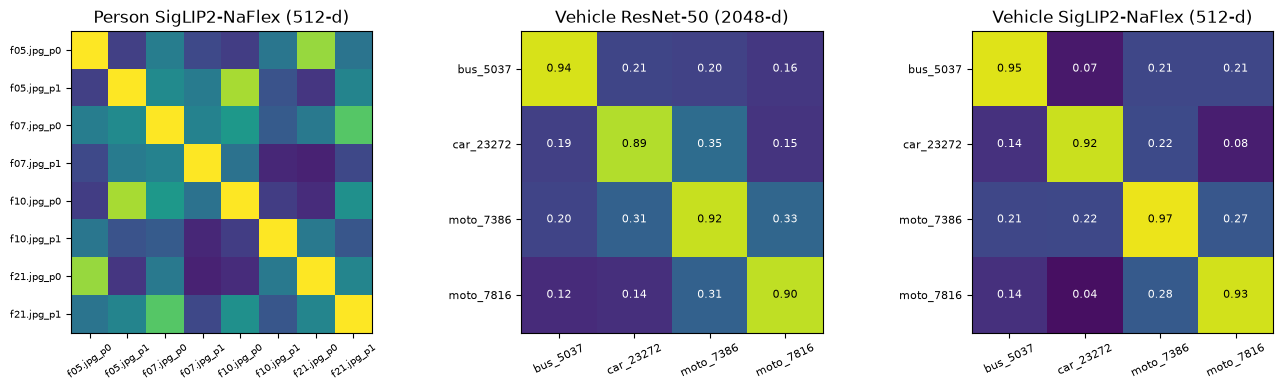

In [4]:
from perception.modules.mtmc.core import _reid

# Fetch 4 distinct public COCO val2017 traffic vehicle images once into notebooks/downloads/samples_cache/
VEHICLE_SPECS = [
    ("bus_5037",   "http://images.cocodataset.org/val2017/000000005037.jpg", (6,)),
    ("car_23272",  "http://images.cocodataset.org/val2017/000000023272.jpg", (3, 8)),
    ("moto_7386",  "http://images.cocodataset.org/val2017/000000007386.jpg", (4,)),
    ("moto_7816",  "http://images.cocodataset.org/val2017/000000007816.jpg", (4,)),
]

vehicle_crops = []
with torch.no_grad():
    for name, url, target_cls in VEHICLE_SPECS:
        local_img = SAMPLES_CACHE / f"{name}.jpg"
        if not local_img.exists():
            urllib.request.urlretrieve(url, local_img)
        bgr = cv2.imread(str(local_img))
        t = torch.from_numpy(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)).permute(2, 0, 1).float().cuda() / 255.0
        out = det([t])[0]
        labs, scs, bxs = out["labels"].cpu().numpy(), out["scores"].cpu().numpy(), out["boxes"].cpu().numpy()
        hits = [bxs[i] for i in range(len(scs)) if int(labs[i]) in target_cls and scs[i] >= 0.45]
        x1, y1, x2, y2 = [max(0, int(round(v))) for v in hits[0]]
        vehicle_crops.append((name, bgr[y1:y2, x1:x2]))

# Point ReIDEngine at our notebooks/downloads/models_cache/torch copy of resnet50-11ad3fa6.pth (exact same file & sha prefix)
_ = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
cached_r50 = TORCH_CACHE / "checkpoints" / "resnet50-11ad3fa6.pth"
assert cached_r50.is_file()

orig_weights = _reid.REID_WEIGHTS
try:
    _reid.REID_WEIGHTS = cached_r50
    cfg = type("Cfg", (), {"reid_embed_stride": 1, "reid_max_crops": 16, "reid_batch_size": 16})()
    r50_engine = _reid.ReIDEngine(cfg)
    assert r50_engine.ensure_loaded() is True
finally:
    _reid.REID_WEIGHTS = orig_weights

v_raw = [c for _, c in vehicle_crops]
# Cross-camera / day-to-night style perturbation: horizontal flip + brightness/contrast shift + 6% crop trim
v_shifted = []
for c in v_raw:
    ch, cw = c.shape[:2]
    trimmed = c[int(ch*0.03):int(ch*0.97), int(cw*0.03):int(cw*0.97)]
    shifted = cv2.flip(np.clip(trimmed.astype(np.float32) * 0.70 + 15.0, 0, 255).astype(np.uint8), 1)
    v_shifted.append(shifted)

# Benchmark ResNet-50 (_reid.ReIDEngine) latency & embeddings
for _ in range(5):
    r50_engine.embed_crops(v_raw[:1])
t0 = time.perf_counter()
for _ in range(30):
    r50_engine.embed_crops(v_raw[:1])
r50_ms_b1 = (time.perf_counter() - t0) * 1000.0 / 30

emb_r50_raw = r50_engine.embed_crops(v_raw)
emb_r50_shf = r50_engine.embed_crops(v_shifted)
emb_v_raw, v_shapes = naflex_ort_embed(v_sess, v_raw)
emb_v_shf, _ = naflex_ort_embed(v_sess, v_shifted)

assert emb_r50_raw.shape == (4, 2048) and emb_v_raw.shape == (4, 512)

def summarize_sep(name, a, b):
    mat = a @ b.T
    same = np.diag(mat)
    diff = mat[~np.eye(len(a), dtype=bool)]
    margin = float(same.min() - diff.max())
    print(f"{name:34s} | same min={same.min():.3f} mean={same.mean():.3f} | diff max={diff.max():.3f} mean={diff.mean():.3f} | margin={margin:+.3f}")
    return mat

mat_r50 = summarize_sep("IRIS ResNet-50 (BSD-3, 2048-d)", emb_r50_raw, emb_r50_shf)
mat_sig = summarize_sep("Occurra Vehicle NaFlex (512-d)", emb_v_raw, emb_v_shf)
print(f"Vehicle latency -> ResNet-50 PyTorch b=1: {r50_ms_b1:.2f} ms | SigLIP2-NaFlex ORT CUDA b=1: {v_ms_b1:.2f} ms | b=8: {v_ms_b8/8:.2f} ms/crop")
print("NaFlex vehicle spatial patch grids:", v_shapes.tolist())

# Visual summary: Person crops + Similarity Matrices (Person NaFlex + Vehicle ResNet50 vs SigLIP2)
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0))
im0 = axes[0].imshow(sim_pp, vmin=0.0, vmax=1.0, cmap="viridis")
p_labels = [c[0] for c in person_crops]
axes[0].set_xticks(range(len(p_labels))); axes[0].set_xticklabels(p_labels, rotation=35, fontsize=7)
axes[0].set_yticks(range(len(p_labels))); axes[0].set_yticklabels(p_labels, fontsize=7)
axes[0].set_title("Person SigLIP2-NaFlex (512-d)")

v_labels = [n for n, _ in vehicle_crops]
for ax, mat, title in [(axes[1], mat_r50, "Vehicle ResNet-50 (2048-d)"),
                       (axes[2], mat_sig, "Vehicle SigLIP2-NaFlex (512-d)")]:
    ax.imshow(mat, vmin=0.0, vmax=1.0, cmap="viridis")
    ax.set_xticks(range(4)); ax.set_xticklabels(v_labels, rotation=25, fontsize=8)
    ax.set_yticks(range(4)); ax.set_yticklabels(v_labels, fontsize=8)
    ax.set_title(title)
    for r in range(4):
        for c in range(4):
            ax.text(c, r, f"{mat[r, c]:.2f}", ha="center", va="center",
                    color="white" if mat[r, c] < 0.65 else "black", fontsize=8)
plt.tight_layout(); plt.show()


## 4. Codebase Readiness Verdict & Migration Checklist


In [5]:
print("=" * 78)
print("TASK 6 VERIFICATION SUMMARY (Commercial Person & Vehicle Re-ID)")
print("=" * 78)
print(f"6A Person Re-ID  : occurra/person_reid_siglip2_naflex_512d (Apache-2.0, 512-d ONNX)")
print(f"   ORT CUDA Speed: b=1 {p_ms_b1:.2f} ms ({1000/p_ms_b1:.1f} crops/s) | b=8 {p_ms_b8:.2f} ms ({p_ms_b8/8:.2f} ms/crop)")
print(f"   Signal quality: same-ID (crop+lighting) min={same_p.min():.3f} mean={same_p.mean():.3f}")
print(f"   Codebase fit  : AppearanceWorker redis schema works unchanged with 512-d float16 bytes,")
print(f"                   BUT perception/modules/appearance/worker.py onnx_embedder() only passes")
print(f"                   1 input -> must add naflex_onnx_embedder() + crop guard (min 32px, <=5:1).")
print(f"                   Also update downstream Barber cosine consumer for 256-d -> 512-d re-index.")
print(f"6B Vehicle Re-ID : occurra/vehicle_reid_siglip2_naflex_512d (Apache-2.0, 512-d) vs ResNet-50 (BSD-3)")
print(f"   Latency b=1   : SigLIP2 ORT {v_ms_b1:.2f} ms (b=8 {v_ms_b8/8:.2f} ms/crop) vs ResNet-50 PyTorch {r50_ms_b1:.2f} ms")
print(f"   Cross-view sep: SigLIP2 same_min={np.diag(mat_sig).min():.3f}, diff_max={mat_sig[~np.eye(4, dtype=bool)].max():.3f}")
print(f"                   ResNet50 same_min={np.diag(mat_r50).min():.3f}, diff_max={mat_r50[~np.eye(4, dtype=bool)].max():.3f}")
print(f"   Codebase fit  : Keep resnet50-11ad3fa6.pth (BSD-3) as zero-risk fallback; add NaFlex ONNX")
print(f"                   entry to mtmc/reid_models.py & calibrate MTMC reid_sim_threshold vs 0.55.")
print("=" * 78)


TASK 6 VERIFICATION SUMMARY (Commercial Person & Vehicle Re-ID)
6A Person Re-ID  : occurra/person_reid_siglip2_naflex_512d (Apache-2.0, 512-d ONNX)
   ORT CUDA Speed: b=1 24.25 ms (41.2 crops/s) | b=8 166.36 ms (20.80 ms/crop)
   Signal quality: same-ID (crop+lighting) min=0.964 mean=0.976
   Codebase fit  : AppearanceWorker redis schema works unchanged with 512-d float16 bytes,
                   BUT perception/modules/appearance/worker.py onnx_embedder() only passes
                   1 input -> must add naflex_onnx_embedder() + crop guard (min 32px, <=5:1).
                   Also update downstream Barber cosine consumer for 256-d -> 512-d re-index.
6B Vehicle Re-ID : occurra/vehicle_reid_siglip2_naflex_512d (Apache-2.0, 512-d) vs ResNet-50 (BSD-3)
   Latency b=1   : SigLIP2 ORT 24.09 ms (b=8 20.88 ms/crop) vs ResNet-50 PyTorch 19.52 ms
   Cross-view sep: SigLIP2 same_min=0.921, diff_max=0.283
                   ResNet50 same_min=0.886, diff_max=0.354
   Codebase fit  : Keep resnet5